<a href="https://colab.research.google.com/github/petiay/astropysu/blob/ynmar28/2026_Inst_Astro_python_astrostats_github_pymj.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Петя Я: Мисия „Рожен“: Открий скрития сигнал! 🌌

**Интерактивна игра с Python и астростатистика | за начинаещи | 50–60 минути (според темпото)**

*Това е учебна симулация, вдъхновена от радиоастрономията. Данните НЕ са измервания от LOFAR или НАО „Рожен“.*

### Как работим в Google Colab
1. Отвори тетрадката в **Google Colab**. Ако е само за четене: **File → Save a copy in Drive**.
2. За да изпълниш клетка: натисни **▶** или **Shift + Enter**.
3. Променяй само числата и параметрите в означените клетки. Няма проблем да сбъркаш!
4. Ако нещо се обърка: **Runtime → Restart session** и пусни клетките от началото.
5. Кажи в **Zoom chat** какви резултати си получил/а.

**План:** първо звездна карта и диаграма цвят–величина (CMD), после откриване на радиосигнал сред шум.

**Основни термини:** *cell* (клетка), *variable* (променлива), *function* (функция), *library* (библиотека), *plot* (графика), *noise* (шум), *signal* (сигнал).

## 1. Първи 30 секунди с Python

Промени името и числото. После стартирай клетката.

*Variable (променлива)* = име, на което даваме стойност. *Print* = показваме резултата.

In [15]:
person = "Петя"        # замени с твоето име
objects = 27               # избери друго число
print("Здравей,", person + "!")
print("Открила си", objects, "звезди и утре ще откриеш", objects + 1, "!")

Здравей, Петя!
Открила си 27 звезди и утре ще откриеш 28 !


## 2. Създай звездна карта **и** диаграма цвят–величина (CMD)! ✨

С един Python код ще покажем **едни и същи симулирани звезди по два начина**:

- **Вляво — звездна карта (sky map):** къде са звездите. Размерът на точките е само графичен символ — **не е физически размер** на звезда.
- **Вдясно — диаграма цвят–величина (color–magnitude diagram, CMD):** на хоризонталната ос е **цветовият индекс** от **−2 (син)** до **+5 (червен/кафеникав)**; на вертикалната ос е **видимата звездна величина (apparent magnitude)** от **15 до 30**. **15 е отгоре (по-ярко), а 30 — отдолу (по-слабо)**.

| Променлива | Какво прави? |
|---|---|
| `number_of_stars` | Брой звезди / number of stars |
| `star_size` | Размер на точките на картата / marker size |
| `star_color` | Цветова палитра / colormap (започни с `turbo`) |
| `blue_size_boost` | Колко да увеличим **сините** точки на картата |
| `star_seed` | Генерира нова случайна звездна популация |

**Начин на работа:** промени една настройка и натисни **▶** или **Shift + Enter**. Не е необходимо да редактираш кода под настройките.

*Важно: данните и двете звездни популации са учебна симулация. Цветовият индекс и палитрата `turbo` са за илюстрация, а не физически калибрирана връзка между цвят и спектър.*

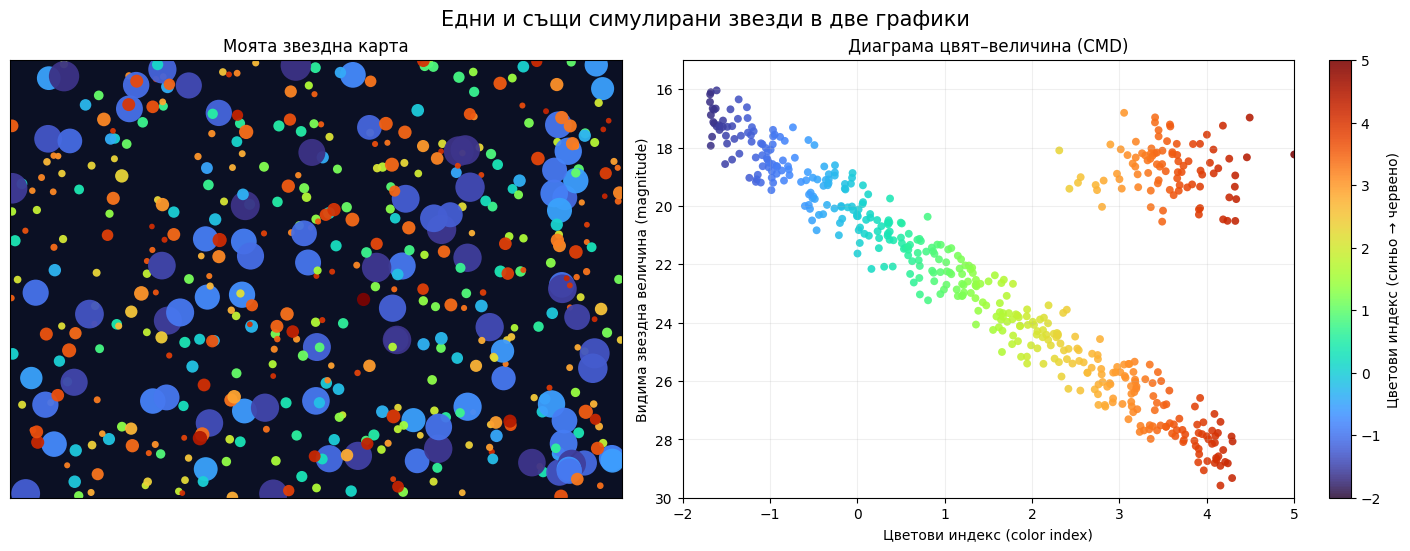

In [14]:
import numpy as np                   # NumPy: числа и случайни стойности
import matplotlib.pyplot as plt      # Matplotlib: графики

# ▼ ПРОМЕНЯЙ САМО ТЕЗИ НАСТРОЙКИ ▼
number_of_stars = 500   # @param {type:"slider", min:20, max:500, step:20}
star_size = 90          # @param {type:"slider", min:20, max:200, step:10}
star_color = "turbo"    # @param ["turbo", "plasma", "viridis", "cool"]
blue_size_boost = 4.0  # @param {type:"slider", min:1.0, max:5.0, step:0.5}
star_seed = 4           # @param {type:"integer"}
# ▲ ДОТУК — ОСТАНАЛОТО Е ПОДГОТВЕН КОД ▲

# Едни и същи звезди: случайни позиции + симулирани цвят и величина.
rng_stars = np.random.default_rng(star_seed)
x_stars = rng_stars.uniform(0, 100, number_of_stars)
y_stars = rng_stars.uniform(0, 100, number_of_stars)

# Опростена звездна популация: главна последователност + червени гиганти.
n_main = int(number_of_stars * 0.82)
n_giants = number_of_stars - n_main
color_main = rng_stars.uniform(-1.7, 4.3, n_main)
mag_main = 16.9 + 1.95 * (color_main + 1.7) + rng_stars.normal(0, 0.7, n_main)
color_giants = np.clip(rng_stars.normal(3.6, 0.55, n_giants), -2, 5)
mag_giants = rng_stars.normal(18.8, 0.9, n_giants)

star_index = np.concatenate([color_main, color_giants])
star_magnitude = np.clip(np.concatenate([mag_main, mag_giants]), 15, 30)

# По-малка звездна величина = по-ярък видим източник.
apparent_brightness = (30 - star_magnitude) / (30 - 15)
marker_sizes = star_size * (0.18 + 1.35 * apparent_brightness**2)
marker_sizes[star_index < -0.5] *= blue_size_boost  # увеличава сините точки

# Двете графики използват еднакви звезди и една цветова скала.
fig, (ax_sky, ax_cmd) = plt.subplots(1, 2, figsize=(14, 5.4),
                                      layout="constrained")

# 1. Карта на небето
ax_sky.set_facecolor("#0b1024")
ax_sky.scatter(x_stars, y_stars, c=star_index, s=marker_sizes,
               cmap=star_color, vmin=-2, vmax=5, alpha=0.95, edgecolors="none")
ax_sky.set(xlim=(0, 100), ylim=(0, 100), title="Моята звездна карта")
ax_sky.set_xticks([])
ax_sky.set_yticks([])

# 2. Диаграма цвят–величина / CMD
points = ax_cmd.scatter(star_index, star_magnitude, c=star_index,
                        s=32, cmap=star_color, vmin=-2, vmax=5,
                        alpha=0.88, edgecolors="none")
ax_cmd.set(xlim=(-2, 5), ylim=(30, 15),
           xlabel="Цветови индекс (color index)",
           ylabel="Видима звездна величина (magnitude)",
           title="Диаграма цвят–величина (CMD)")
ax_cmd.grid(alpha=0.20)
bar = fig.colorbar(points, ax=ax_cmd, ticks=np.arange(-2, 6))
bar.set_label("Цветови индекс (синьо → червено)")

fig.suptitle("Едни и същи симулирани звезди в две графики", fontsize=15)
plt.show()


### Минипредизвикателство: две графики, един набор от звезди (6–8 минути)

1. Направи **рядко небе**: `number_of_stars = 40`, `star_size = 40`. Виж колко точки има на **всяка** от двете графики.
2. Направи **гъсто небе**: `number_of_stars = 300`, `star_size = 140`. Променя ли се общата форма на CMD?
3. Направи **сините звезди по-големи**: `blue_size_boost = 4`. Променя ли се мястото им на CMD, или само размерът на маркерите на звездната карта?
4. Смени `star_color` от `"turbo"` на `"plasma"`. **Променят ли се данните, или само визуализацията?**

**Въпроси за Zoom chat:** Защо стойност 15 е **по-нагоре** от 30? Къде на CMD са по-сините звезди? Кои точки може да са червени гиганти?

**Бележка за преподавателя:** В истински CMD цветът често е разлика между две фотометрични величини (например *BP−RP*). Тук използваме **опростен цветови индекс**, не действителни измервания. Не бива да се приема, че цветът на точката в `turbo` съвпада с реалния видим цвят на звездата. Обърнатата вертикална ос е **астрономическа конвенция**.

---
# 3. Основната мисия: скрит източник сред шум

Радиотелескопите регистрират сигнали, но наблюденията включват и **шум (noise)**. Ще създадем квадратна карта с **един изкуствен източник** и случайни смущения.

**Твоята задача:** познай къде е източникът. После направи сигнала толкова слаб, че да го различиш трудно!

### Подготвителен код (не е необходимо да го разбирате целия)

Изпълни тази клетка **веднъж**. Тя създава функция, която симулира наблюдение. Това е пример защо ползваме функции и готови библиотеки.

In [16]:
def simulate_radio_map(strength=9, noise=2, x0=28, y0=34,
                       source_width=3.5, seed=7, source_present=True):
    """Учебна 2D карта: гаусов източник + независим нормален шум."""
    N = 60
    yy, xx = np.mgrid[0:N, 0:N]
    rng = np.random.default_rng(seed)
    sky = (float(strength) * np.exp(-((xx-x0)**2 + (yy-y0)**2)
                                  / (2*source_width**2))
           if source_present else np.zeros((N, N)))
    noise_map = rng.normal(0.0, float(noise), size=(N, N))
    return sky + noise_map, sky

def show_map(data, cmap="magma", title="Симулирано радио небе"):
    fig, ax = plt.subplots(figsize=(7, 5.8))
    im = ax.imshow(data, origin="lower", cmap=cmap, interpolation="nearest")
    ax.set(xlabel="x (пиксели)", ylabel="y (пиксели)", title=title)
    fig.colorbar(im, ax=ax, label="Условна яркост")
    plt.tight_layout()
    plt.show()

print("Готово — симулаторът работи!")

Готово — симулаторът работи!


## 4. Ниво 1: намери яркия източник

**Смени само стойностите по-долу.** В Colab може да се появят плъзгачи (*sliders*) и меню за цветовете.

За начало: `signal_strength = 10`, `noise_level = 2`, `source_x = 30`, `source_y = 30`.

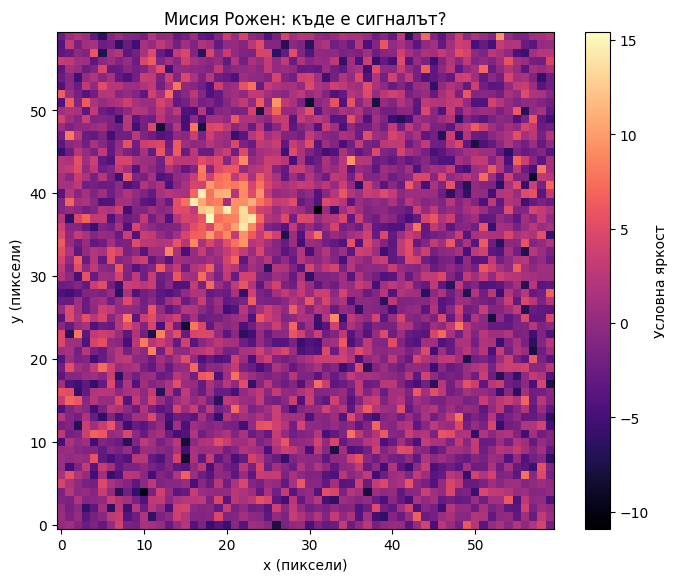

[[2.46532465e-32 1.21115584e-31 5.48369545e-31 ... 1.64090788e-49
  7.68442361e-51 3.31654415e-52]
 [5.26437747e-31 2.58626446e-30 1.17097125e-29 ... 3.50394358e-48
  1.64090788e-49 7.08204508e-51]
 [1.03601803e-29 5.08971219e-29 2.30444594e-28 ... 6.89568474e-47
  3.22927101e-48 1.39373106e-49]
 ...
 [3.88564257e-13 1.90892453e-12 8.64295115e-12 ... 2.58626446e-30
  1.21115584e-31 5.22726495e-33]
 [7.90927979e-14 3.88564257e-13 1.75928479e-12 ... 5.26437747e-31
  2.46532465e-32 1.06401709e-33]
 [1.48374210e-14 7.28927489e-14 3.30033198e-13 ... 9.87571393e-32
  4.62482813e-33 1.99604387e-34]]


In [34]:
signal_strength = 12   # @param {type:"slider", min:0, max:20, step:1}
noise_level = 3         # @param {type:"slider", min:0.5, max:8, step:0.5}
source_x = 20           # @param {type:"slider", min:8, max:52, step:1}
source_y = 38           # @param {type:"slider", min:8, max:52, step:1}
color_map = "magma"    # @param ["magma", "viridis", "plasma", "turbo", "inferno"]
random_seed = 7         # @param {type:"integer"}

observation, true_signal = simulate_radio_map(
    signal_strength, noise_level, source_x, source_y, seed=random_seed)
show_map(observation, cmap=color_map, title="Мисия Рожен: къде е сигналът?")

print(true_signal)

**Бързи предизвикателства**

- Постави източника в друг ъгъл на картата — променя ли се местоположението на яркото петно?
- Пробвай `magma`, `viridis`, `turbo` — **сменя ли се реалният сигнал или само начинът на представяне?**
- Напиши в Zoom chat две числа: `signal_strength` и `noise_level`.

## 5. Ниво 2: колко слаб сигнал можеш да видиш?

Промени в **предишната клетка** `signal_strength` на 5, после 3, после 1; пробвай и `noise_level = 4`. Стартирай предишната клетка отново.

**Въпрос:** В кой момент вече не си сигурен/сигурна, че виждаш източник?

### Малко астростатистика: mean, standard deviation и histogram

- **Средна стойност (mean):** средното от много измервания.
- **Стандартно отклонение (standard deviation, σ):** колко се разпръскват стойностите.
- **Хистограма (histogram):** колко често виждаме различни стойности.

Тук измерваме фона **извън зоната на известния симулиран източник**. Това е улеснение за обучение.

-0.05056452488129309


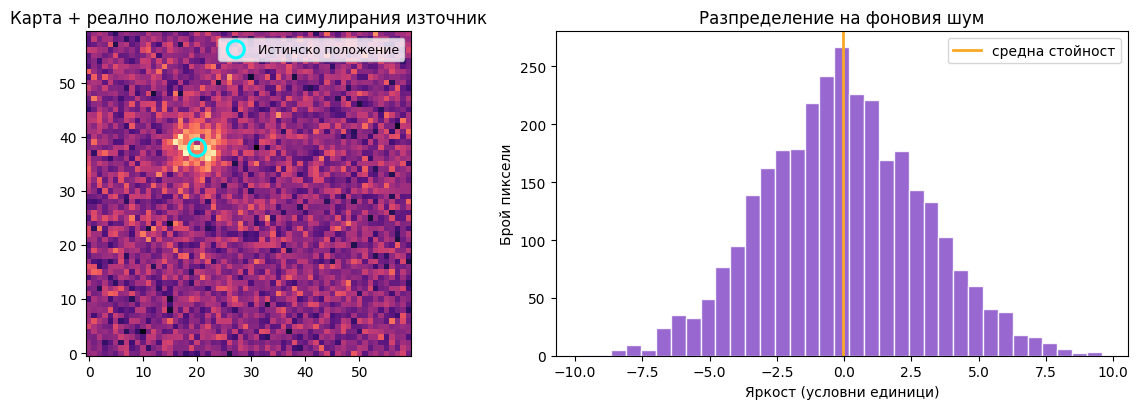

Средно ниво на фона: -0.05
Стандартно отклонение на фона: 2.96
Учебна оценка на сигнал/шум в известния център: 4.92


In [37]:
N = observation.shape[0]
yy, xx = np.mgrid[0:N, 0:N]
background_pixels = observation[(xx-source_x)**2 + (yy-source_y)**2 > 12**2]
bg_mean = np.mean(background_pixels)
print(bg_mean)
bg_std = np.std(background_pixels)
center_value = observation[source_y, source_x]
example_snr = (center_value - bg_mean) / bg_std

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
axs[0].imshow(observation, origin="lower", cmap=color_map)
axs[0].scatter([source_x], [source_y], s=150, facecolors="none",
               edgecolors="cyan", linewidths=2.2, label="Истинско положение")
axs[0].legend(loc="upper right", fontsize=9)
axs[0].set_title("Карта + реално положение на симулирания източник")
axs[1].hist(background_pixels, bins=35, color="#8951c9",
            alpha=0.87, edgecolor="white")
axs[1].axvline(bg_mean, color="#f9a825", lw=2, label="средна стойност")
axs[1].set(xlabel="Яркост (условни единици)", ylabel="Брой пиксели",
           title="Разпределение на фоновия шум")
axs[1].legend()
plt.tight_layout(); plt.show()
print(f"Средно ниво на фона: {bg_mean:.2f}")
print(f"Стандартно отклонение на фона: {bg_std:.2f}")
print(f"Учебна оценка на сигнал/шум в известния център: {example_snr:.2f}")

**Важно:** Това е опростена **учебна** оценка на *signal-to-noise ratio (SNR)* в **предварително известна позиция**. При истински научни търсения трябва да се отчита как избираме кандидатите, колко места проверяваме, какви са шумът и систематичните грешки. Висока стойност сама по себе си не доказва нов обект.

## 6. Ниво 3: фалшива тревога!

**Какво ако изобщо няма източник?** Случайният шум понякога образува ярки петна. На картата по-долу има **само шум**.

Въпрос за чата: „Откри ли някаква ярка точка? Значи ли тя, че има истински източник?“

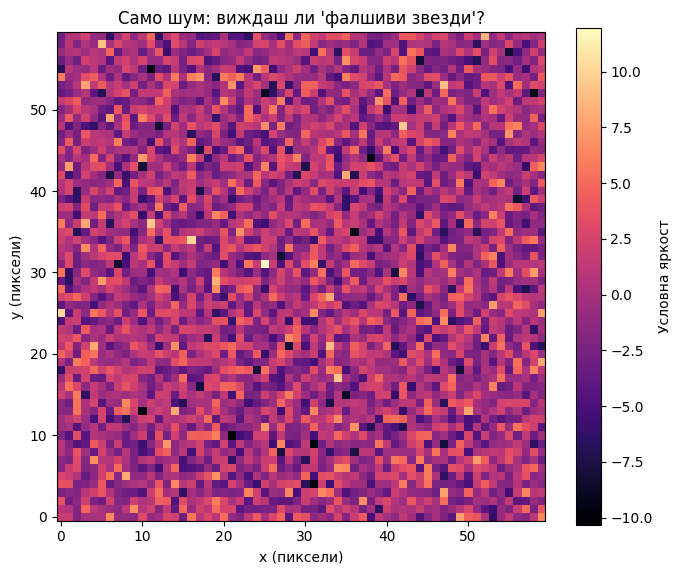

Най-яркият пиксел е 11.95.
Стандартното отклонение е 3.05.
Внимание: големи случайни пикове се появяват при търсене в хиляди пиксели!


In [41]:
random_seed = 4
noise_only, _ = simulate_radio_map(strength=0, noise=noise_level,
                                     seed=random_seed + 100, source_present=False)
show_map(noise_only, cmap=color_map, title="Само шум: виждаш ли 'фалшиви звезди'?")
print(f"Най-яркият пиксел е {noise_only.max():.2f}.")
print(f"Стандартното отклонение е {noise_only.std():.2f}.")
print("Внимание: големи случайни пикове се появяват при търсене в хиляди пиксели!")

### Бонус: помага ли да наблюдаваме по-дълго?

Ще комбинираме няколко **независими симулирани измервания** на един и същ непроменящ се източник. Случайният шум в усреднената карта обикновено намалява.

Избери `number_of_observations = 1`, после 4, после 16.

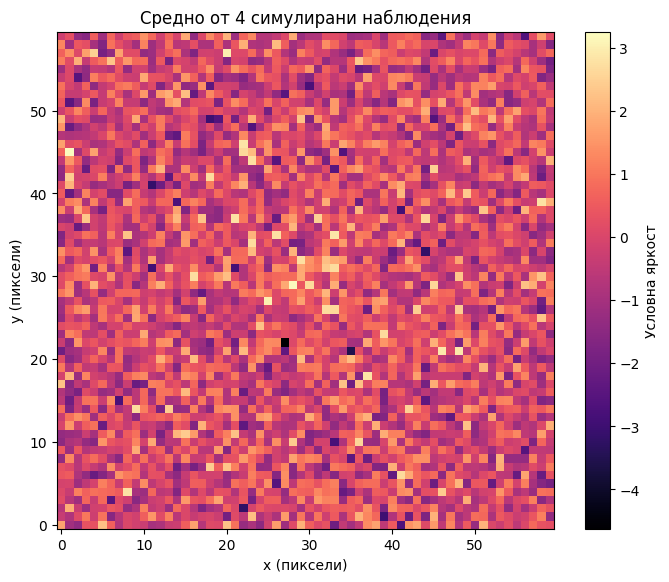

Очакван шум в усреднената карта (приблизително): 1.0


In [50]:
number_of_observations = 4  # @param [1, 4, 16, 36] {type:"raw"}
source_for_average = 1      # @param {type:"slider", min:0, max:15, step:1}
noise_for_average = 2       # @param {type:"slider", min:1, max:8, step:1}

stack = []
for i in range(number_of_observations):
    obs, _ = simulate_radio_map(source_for_average, noise_for_average, 30, 30, seed=200+i)
    stack.append(obs)
average_observation = np.mean(stack, axis=0)
show_map(average_observation, title=f"Средно от {number_of_observations} симулирани наблюдения")
print("Очакван шум в усреднената карта (приблизително):",
      round(noise_for_average / np.sqrt(number_of_observations), 2))

## Финал: ти вече правиш първи стъпки в науката!

Днес използва:
- **Python**: променливи, функции, библиотеки и графики;
- **Звездна популация и CMD**: цвят, звездна величина и две представяния на еднакви данни;
- **Статистика**: mean, standard deviation, histogram, SNR;
- **Научен подход**: задаваш въпрос → правиш измерване/симулация → сравняваш → проверяваш.

**За следващия път:** как истински радиотелескопи като LOFAR събират и обработват данни?

**GitHub:** можеш да качиш своя `.ipynb` файл в хранилище. Не качвай пароли или чувствителни данни.

**Ресурси:** [Google Colab](https://colab.research.google.com/), [Python](https://www.python.org/), [NumPy](https://numpy.org/), [Matplotlib](https://matplotlib.org/), [Astropy](https://www.astropy.org/), [BEAST](https://github.com/BEAST-Fitting/beast).